# 🎓 第4章 第2课：模型比较 —— GRS 体检

**本节目标**：用同一组测试资产，比较七个多因子模型。

- **GRS**：所有测试资产的 α 是否联合为零？p 值大 → 模型通过体检；
- **平均 |α|**：模型解释不了的收益差异有多大；
- **平均 R²**：模型能解释多少收益波动。

对应原书 4.1~4.7 节。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.data import load_ashare_panel
from factor_zero.factors import build_factor_returns
from factor_zero.models import (
    MODEL_DEFINITIONS, model_factor_frame, build_test_assets,
    evaluate_model, compare_models,
)
from factor_zero.regression import fama_macbeth, time_series_betas
from factor_zero.statistics import factor_summary

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


In [2]:
panel = load_ashare_panel()
factors = build_factor_returns(panel, n_groups=10)
assets = build_test_assets(panel, n_groups=5)
print('测试资产:', assets.shape[1], '个组合')
print('样本期:', assets.dropna().index.min().date(), '→', assets.dropna().index.max().date())
assets.iloc[:3, :5].round(4)

测试资产: 15 个组合
样本期: 2019-03-31 → 2024-12-31


,BM_1,BM_2,BM_3,BM_4,BM_5
date,,,,,
2018-02-28,NaN,NaN,NaN,NaN,NaN
2018-03-31,0.0605,0.0240,-0.0357,-0.0372,-0.0523
2018-04-30,-0.0636,-0.0035,-0.0303,-0.0191,-0.0105


## 1) 七个模型的 GRS 比较

对每个模型，把 15 个测试资产（BM/SIZE/MOM 各 5 组）对它做时序回归，
再联合检验所有 α 是否为零。

In [3]:
comp = compare_models(factors, assets)
comp_sorted = comp.sort_values('mean_abs_alpha_ann')
comp_sorted.round(4)

,k,grs_f,grs_p,mean_abs_alpha_ann,avg_r2,periods
model,,,,,,
SY4,4,0.3999,0.9728,0.0233,0.8368,70
Carhart4,4,0.4827,0.9387,0.0252,0.8652,70
FF5,5,0.4728,0.9435,0.0315,0.8398,70
FF3,3,0.5864,0.8720,0.0328,0.8291,70
HXZ4,4,0.4672,0.9464,0.0337,0.7970,70
DHS3,3,0.7236,0.7498,0.0461,0.8070,70
NovyMarx4,4,0.8716,0.5979,0.0564,0.8382,70


### 怎么读？

- **grs_p 大**：不能拒绝“α 全为零”，模型通过体检；
- **平均 |α| 小**：模型留下的定价误差小；
- **平均 R² 高**：模型解释的波动多；
- **因子数 k**：越多不一定越好——要看解释力提升是否值得复杂度。

> ⚠️ 本样本 GRS 的 p 值可能都不小（样本短、测试资产少、功效低），
> 这时不要只看 p 值，要结合平均 |α|、R² 和经济学逻辑。

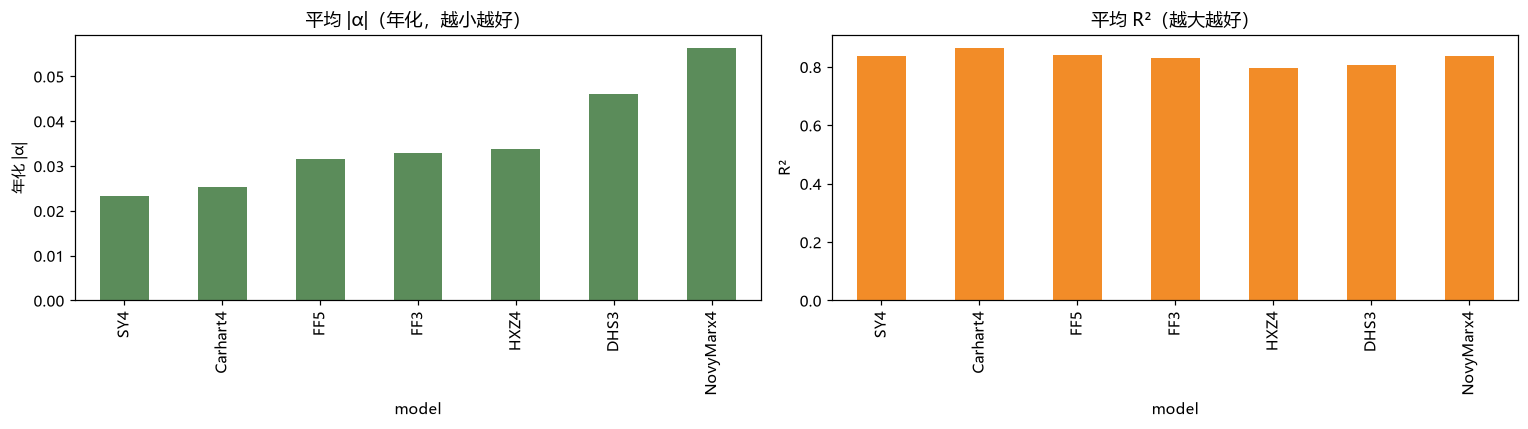

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
comp_sorted['mean_abs_alpha_ann'].plot(kind='bar', ax=axes[0], color='#5B8C5A')
axes[0].set_title('平均 |α|（年化，越小越好）')
axes[0].set_ylabel('年化 |α|')
comp_sorted['avg_r2'].plot(kind='bar', ax=axes[1], color='#F28C28')
axes[1].set_title('平均 R²（越大越好）')
axes[1].set_ylabel('R²')
plt.tight_layout(); plt.show()

## 2) 以 FF3 为例：哪些测试资产的 α 最大？

GRS 只回答“联合是否为零”，不指出具体资产。逐个看 α 可以定位问题。

In [5]:
mf = model_factor_frame(factors, 'FF3')
data = pd.concat([assets, mf], axis=1).dropna()
alphas, betas, resid = time_series_betas(data[assets.columns], data[mf.columns])
alphas_ann = (alphas * 12).sort_values(key=np.abs, ascending=False)
alphas_ann.head(10).round(4)

MOM_1    -0.1123
MOM_4     0.0606
SIZE_4   -0.0554
SIZE_2    0.0400
MOM_5     0.0377
MOM_2    -0.0337
MOM_3     0.0296
BM_2      0.0284
SIZE_3   -0.0252
SIZE_1    0.0234
Name: alpha, dtype: float64

## ✋ 试一试

1. 把测试资产从 5 组改成 10 组，GRS 的 p 值和平均 |α| 怎么变？
2. 把 `SY4`/`DHS3` 从比较中删掉，只看五个“正统”模型，排名变了吗？
3. 用 FF3 的 α 排序，哪些组合最容易被 FF3 错误定价？

## ✅ 本节小结

- GRS 联合检验 α 是否为零，p 值大 → 模型通过；
- p 值不够时，结合平均 |α|、R²、经济学逻辑；
- 因子越多不一定越好，要看解释力提升和简约性；
- SY4/DHS3 在本仓库是近似代理，结果只用于演示。

> 下一课：A 股被定价因子 + 简约性。